# Paper 9 — Building the Market Intelligence Instance in JSON
## Contract-first specification, complete dataflow and lifecycle verification
**30 October 2026 · Specified, not deployed**

### Abstract
Paper 8 established the purpose and five-plane architecture of a Market Intelligence instance, but its JSON left source discovery, data routing, review, costs, state guards and artifact typing underspecified. Paper 9 develops a versioned JSON instance contract with explicit capability ports, producer-to-consumer bindings, typed artifact schemas, evidence-decision policies, review authority, persistence requirements and revision-aware lifecycle rules. A local validator checks the declared design and uses controlled fault cases to expose incomplete bindings and unsafe acceptance. The instance remains within Paper 7's unified Operations plane. Native Langflow component selection and composite internal graphs remain deferred by design. This paper builds and checks the machine-readable specification; it does not run market research, prove source truth, deploy an orchestrator or demonstrate commercial value.

**Deliverables:** canonical instance JSON; JSON Schema artifact and activation definitions; design validator and controlled checks; inspectable notebook and matching visual. **Non-deliverables:** live research agents, source connectors, populated credentials, public activity or business validation.

## 1. Research question, hypotheses and falsification
**Question:** Can the proposed Market Intelligence instance be specified precisely enough that builders need not invent its external behavior when selecting and wiring its internals?

| Hypothesis | Supporting design evidence | What would challenge it |
|---|---|---|
| H1: complete handoffs | Every required input has a declared, type-compatible producer available before use | Unbound inputs, invented observer outputs, impossible ordering |
| H2: honest evidence | Schemas and review policy distinguish sources, observations, candidate claims and judgments | Supported claims without evidence; inaccessible data converted to zero demand |
| H3: bounded lifecycle | Explicit authority, limits and revision gates block unsupported transitions | A missing setting or string 'true' grants access; retry loops escape caps |
| H4: builder preparation | Each composite has a bounded contract and clear deferred internals | Builder must guess source discovery, who approves, or how outputs are accepted |

Passing structural checks supports only the stated representation properties. It cannot prove reasoning quality, access-policy enforcement, storage consistency or profitable audience opportunities. A simpler manual process remains a meaningful future comparison.

## 2. Audit findings carried forward from Paper 8
| Paper 8 gap | Paper 9 treatment | Residual proof still needed |
|---|---|---|
| Source locations appeared without a producer | Source discovery produces a screened candidate batch | Real search/retrieval adapters and quality evaluation |
| Flow arrows without explicit routing | Named typed ports and exact artifact bindings | Runtime delivery, retries and persistence |
| Claims were judged without explicit claim-formation responsibility | Separate candidate-claim formation and evidence judgment | Real entailment and scope review |
| Assembly stood in for review and handoff | Separate reviewer and versioned handoff contracts | Actual role separation and consumer acknowledgment |
| Costs consumed but not generated | Cross-cutting attempt observer produces cost ledger snapshots | Real timing, tariff, allocation and failure records |
| Record names without data types | Closed JSON Schema artifact definitions and conditional requirements | Cross-artifact identity/content verification and runtime enforcement |
| Lifecycle largely prose | States, events, actors, guards, exception and revision routes | Actual orchestrator semantics and crash recovery |
| Inconsistent business reference | Uses Paper 7's canonical business identity | Future integration test against registry |
| Component internals absent | Deliberately remain unbound | Later native catalog and resource grounding |

The Paper 8 notebook and its JSON remain historical design evidence, unchanged. Paper 9's JSON is the new working contract; it is not silently substituted into old diagrams.

## 3. Instance and process contracts
The instance investigates a bounded audience problem and competing solutions for Content Strategy. It recommends continue, narrow, ask, stop or insufficient; it does not autonomously adopt a business or publish/spend.

| Process | Responsibility | Owner role | Important boundary |
|---|---|---|---|
| Governance | Brief, authority and plan | Intelligence owner | Unresolved scope/limits block acquisition |
| Investigation | Discovery, evidence, alternatives, candidate claims and judgment | Intelligence owner | Accessible source evidence is not purchase behavior |
| Review/handoff | Dossier, independent review and acknowledged delivery | Evidence reviewer / declared stage actors | No self-approval or implicit consumer acceptance |
| Refresh/revise | Impact trace and approved child revision | Intelligence owner | Old evidence and unrelated artifacts remain stable |
| Stewardship | Every attempt's costs, access and privacy events | Operations owner | Failed/retried work is not free or invisible |

Roles are declared responsibilities, not deployed agents. Actual authorized actor bindings remain unresolved. The review process contains separately attributed actions; the lifecycle specifies the actor role for review decisions.

In [1]:
from pathlib import Path
import json,sys
from IPython.display import display, JSON
import pandas as pd
repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"knowledge/research/paper-9-study/market-intelligence.instance.json").exists())
study=repo/"knowledge/research/paper-9-study"
sys.path.insert(0,str(study))
from validate_contract import load_spec,load_schema,validate_spec,activation_blockers,validate_artifact,guard_allows,validate_review_acceptance
spec=load_spec()
print("This cell reads a design specification. It does not launch agents, collect sources or execute the business.")
display(JSON(spec,expanded=False))

This cell reads a design specification. It does not launch agents, collect sources or execute the business.


<IPython.core.display.JSON object>

## 4. Flow contracts and exact data dependencies
A binding identifies an external input, an earlier node output, or the cross-cutting observer. This prevents a graph from looking complete while relying on undeclared information. The displayed order is a proposed schedule; independent work may be parallelized later only if dependencies and budgets remain respected.

The investigation flow goes from intake through discovery, retrieval, normalization, comparison, claim formation, assessment, assembly, review and handoff. Refresh is a separate flow, requiring a parent dossier and change notice. Its output requests a new approved investigation revision; it does not wire a same-version cycle.

Empty evidence is permitted as data, with an insufficient or blocked result. A connector failure must not prevent recording the failure and cost. It must not be converted into a claim of no market demand.

In [2]:
pd.set_option("display.max_colwidth",None)
pd.set_option("display.max_rows",100)
composites={x["id"]:x for x in spec["composites"]}
rows=[]
for flow in spec["flows"]:
 for node in flow["nodes"]:
  comp=composites[node["composite_ref"]]
  rows.append({"Flow":flow["id"],"Stage":node["id"],"Capability":comp["name"],"Inputs":json.dumps(node["bindings"]),"Outputs":json.dumps(comp["output_ports"]),"Gate":node.get("additional_gate") or node["entry_gate"]})
display(pd.DataFrame(rows))

,Flow,Stage,Capability,Inputs,Outputs,Gate
0,investigate,intake,Brief-to-plan,"{""brief"": ""input.brief""}","{""plan"": ""plan"", ""obligations"": ""obligation_set""}",runtime_ready
1,investigate,discover,Source discovery,"{""plan"": ""intake.plan""}","{""candidates"": ""discovery_batch""}",dependencies_accepted
2,investigate,retrieve,Evidence retrieval,"{""plan"": ""intake.plan"", ""candidates"": ""discover.candidates""}","{""sources"": ""source_batch""}",dependencies_accepted
3,investigate,normalize,Normalize and group evidence,"{""sources"": ""retrieve.sources""}","{""evidence"": ""evidence_set""}",dependencies_accepted
4,investigate,compare,Existing-solution comparison,"{""brief"": ""input.brief"", ""evidence"": ""normalize.evidence""}","{""alternatives"": ""alternative_set""}",dependencies_accepted
5,investigate,form_claims,Candidate claim formation,"{""brief"": ""input.brief"", ""evidence"": ""normalize.evidence"", ""alternatives"": ""compare.alternatives""}","{""candidates"": ""candidate_claims""}",dependencies_accepted
6,investigate,assess,Evidence judgment,"{""candidates"": ""form_claims.candidates"", ""evidence"": ""normalize.evidence"", ""alternatives"": ""compare.alternatives""}","{""assessments"": ""assessment_set""}",dependencies_accepted
7,investigate,assemble,Dossier assembly,"{""brief"": ""input.brief"", ""plan"": ""intake.plan"", ""evidence"": ""normalize.evidence"", ""alternatives"": ""compare.alternatives"", ""assessments"": ""assess.assessments"", ""obligations"": ""observer.obligations"", ""costs"": ""observer.costs""}","{""dossier"": ""dossier""}",dependencies_accepted
8,investigate,review,Independent review,"{""brief"": ""input.brief"", ""plan"": ""intake.plan"", ""candidates"": ""discover.candidates"", ""sources"": ""retrieve.sources"", ""alternatives"": ""compare.alternatives"", ""dossier"": ""assemble.dossier"", ""evidence"": ""normalize.evidence"", ""assessments"": ""assess.assessments""}","{""review"": ""review_decision""}",dependencies_accepted
9,investigate,handoff,Versioned handoff,"{""dossier"": ""assemble.dossier"", ""review"": ""review.review""}","{""receipt"": ""handoff_receipt""}",review_accepts_exact_revision


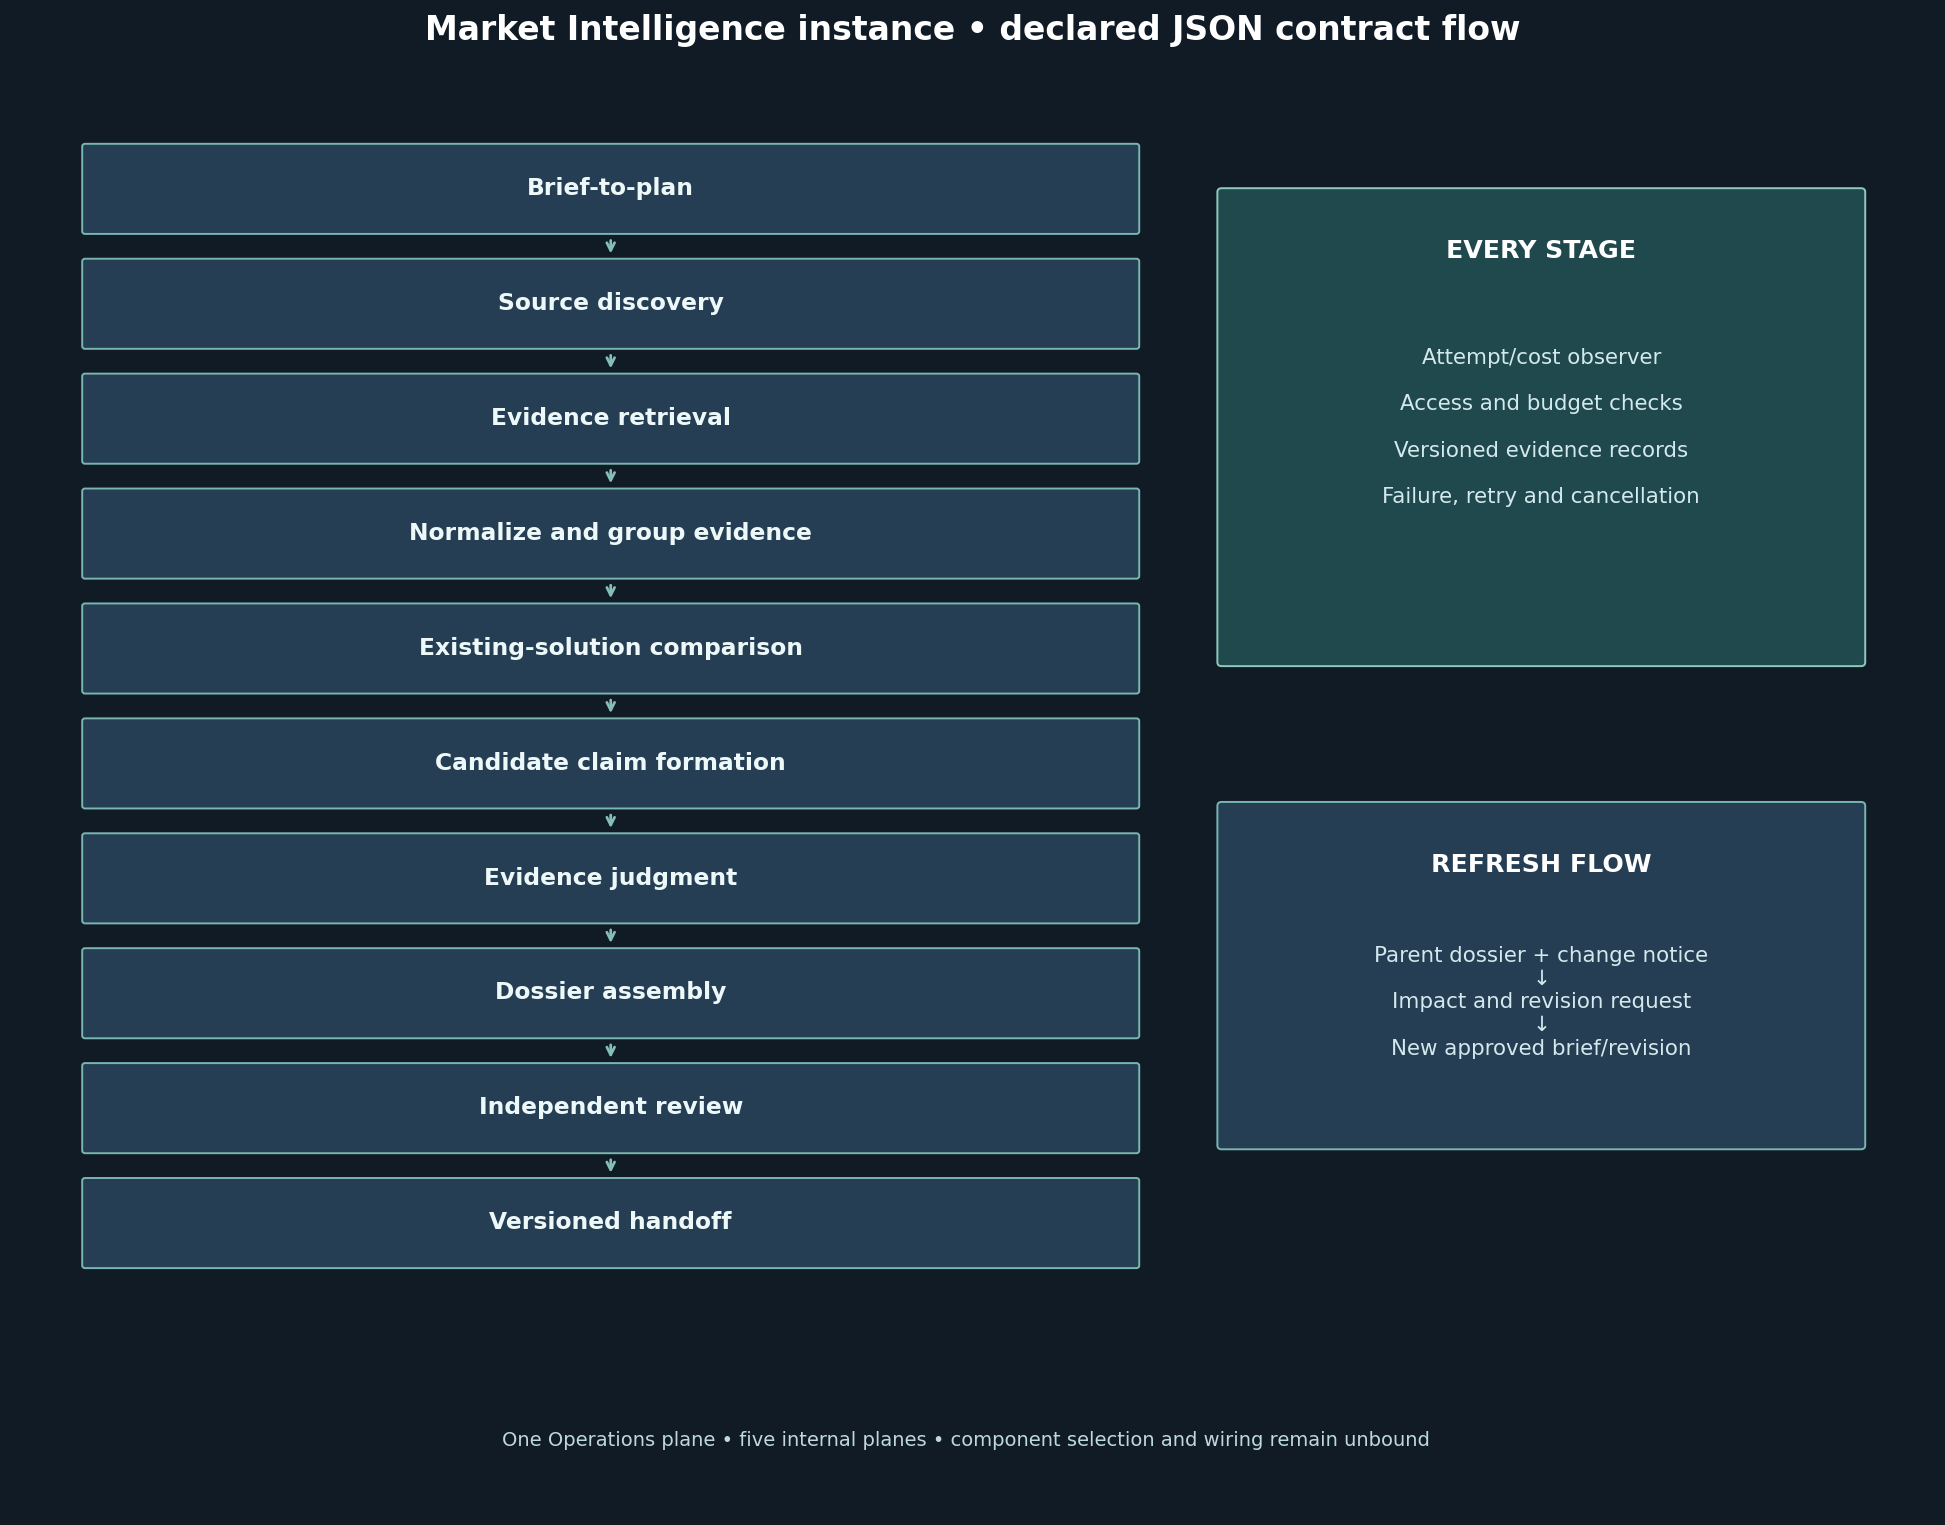

## 5. Composite interfaces, component grounding and configuration
The canonical JSON contains eleven composite interface contracts. Each names required inputs, outputs, responsibility and acceptance policy. All internal graphs are null and all native occurrence references are empty. This preserves the agreed outside-in design boundary. The earlier capability labels are superseded by a more explicit contract set in this paper.

| Plane | What is specified now | What is intentionally unresolved |
|---|---|---|
| Processes | Five owners/responsibilities and stage ownership | Actual authorized actors |
| Flows | Two flows, explicit stage bindings and result bindings | Running executor, dispatch and failure recovery |
| Composites | Eleven capability interfaces and acceptance policies | Native component selection and internal graph |
| Components | Required resource roles and grounding gate | Actual pinned native occurrences/adapters |
| Configuration | Required activation fields, policy and runtime binding structure | Audience, sources, limits, storage, model/runtime and actor values |

Unknown configuration is not silently defaulted. No live collection may begin until activation prerequisites are verified. Contract verification remains permitted in design mode. The following list is expected to be nonempty; it is an honest readiness result, not a failed design test.

In [3]:
errors=validate_spec(spec)
assert errors==[], errors
print("Design reference/type/ownership validation errors:",errors)
blockers=activation_blockers(spec)
display(pd.DataFrame({"Unresolved activation prerequisite":blockers}))
print("Activation ready:",not blockers)
print("An empty design error list does not mean runtime-ready.")

Design reference/type/ownership validation errors: []


,Unresolved activation prerequisite
0,configuration.audience_job
1,configuration.language
2,configuration.geography
3,configuration.time_window
4,configuration.source_connectors
5,configuration.allowed_sources
6,configuration.freshness_window
7,configuration.time_cap_seconds
8,configuration.cash_cap_amount
9,configuration.currency


Activation ready: False
An empty design error list does not mean runtime-ready.


## 6. Artifact schemas and provenance
Artifact definitions use JSON Schema 2020-12 with required fields, closed object properties, explicit arrays/enums, timestamps and conditional requirements. A retrieved source requires a snapshot reference and hash; failed retrieval retains a reason. Supported judgments require evidence, an entailment review and reviewer reference. Acknowledgment requires an acknowledgment record.

These constraints establish record shape, not truth. A validator can require a source reference, but only an artifact registry and inspection can show that the source exists and supports a claim. Conditional 'accepted review' schema checks are supplemented by the complete critical-review rubric check.

| Record group | Purpose | Additional semantic obligation |
|---|---|---|
| Brief/plan/discovery | Scope, query intent and candidate screening | Allowed source/access and bounded search coverage |
| Source/evidence | Actual source capture, observation context, transformations and dependence | Resolve every reference and preserve raw evidence |
| Alternatives/candidate claims/assessments | Separate proposals from judgments | Entailment, scope and contradictory evidence review |
| Dossier/review/receipt | Decision-ready report and attributable acceptance | Exact revision match, reviewer authority and acknowledgment |
| Costs/obligations/change/impact/revision | Honest limits, accounting and controlled change | Real events, no duplicated costs, approved immutable revisions |

The record contracts retain unknown amounts, uncertain independence and empty evidence without inventing values. No source URL is treated as an immutable snapshot. A separate activation schema rejects unresolved or wrongly typed limits and requires real role/runtime bindings; passing this schema still cannot prove that those bindings are authorized or functional. External metrics require source-preserved units/period/context; extending metric-specific schema is required before accepting analytics as a direct connector input.

In [4]:
schemas=load_schema()
from jsonschema import Draft202012Validator
Draft202012Validator.check_schema(schemas)
display(pd.DataFrame([{"Artifact type":k,"Required payload fields":", ".join(v["properties"]["payload"]["required"])} for k,v in schemas["$defs"].items()]))
print("Artifact schema grammar valid. Cross-artifact facts and source truth remain separate checks.")

,Artifact type,Required payload fields
0,brief,"question, audience_job, language, geography, time_window, decision_owner, allowed_source_classes"
1,plan,"brief_ref, queries, inclusion_rules, exclusion_rules, stop_policy_ref, amendment_reason"
2,discovery_batch,"plan_ref, candidates, coverage_limits"
3,source_batch,"discovery_ref, sources, attempt_refs"
4,evidence_set,"sources_ref, observations, family_decisions"
5,alternative_set,"brief_ref, alternatives, search_limits"
6,candidate_claims,claims
7,assessment_set,"candidate_ref, judgments, policy_ref"
8,obligation_set,items
9,cost_ledger,"events, accounting_limits"


Artifact schema grammar valid. Cross-artifact facts and source truth remain separate checks.


## 7. Evidence and decision mechanism
| Stage | Proposed decision procedure | What it cannot infer |
|---|---|---|
| Discover | Run accepted support, counterevidence and existing-solution queries; record candidates/exclusions/limits | Search rank is not demand |
| Normalize | Preserve source and context; record unit/period and reversible transform | A parsed value is not necessarily meaningful |
| Group sources | Flag exact duplicates; review family/syndication links; preserve unknown dependence | Many pages do not imply many independent sources |
| Form claims | Explicitly label observation, inference or hypothesis, with references and scope | Candidate wording is not established fact |
| Assess | Supported, contradicted, mixed, insufficient, stale or inaccessible with reasons | A numeric score or majority vote cannot establish truth |
| Review | Verify provenance, entailment, counterevidence, dependence, scope, costs and privacy | Separate model contexts do not guarantee independent judgment |
| Recommend | Continue/narrow/ask/stop/insufficient within brief and evidence limits | No automatic profitable-niche selection |

Detailed acceptance policies are in the instance JSON. Human or model reviewers must record reasons; factual entailment and material contradictions remain judgment tasks requiring empirical evaluation. Schema checks cannot replace them. This paper does not invent a universal confidence threshold or calibrate unsupported probabilities.

## 8. Lifecycle, authority, failure and recovery
The JSON specifies states, events, actor roles, guard references and cross-cutting exception routes. Guard context is Boolean evidence supplied by named systems: configuration/authority/registry/budget/review records. Missing values and text such as 'true' do not grant permission. The local guard evaluator illustrates these contract semantics; a deployed controller must enforce them independently.

| Situation | Required outcome |
|---|---|
| Missing scope | Clarification obligation; no collection |
| Limit/access failure | Record attempt/cost and block; no authorization bypass |
| Retrieval unavailable | Retain failure; allow qualified insufficient output |
| Review fails | Reject or request a child revision; preserve submission |
| Delivery fails | Preserve accepted dossier; bounded duplicate-safe retry |
| New evidence | Impact report, approved new brief and immutable child revision |
| Cancellation | Propagate to leased work, record partial costs and artifacts |

The dossier carries a cost snapshot through assembly. Review and delivery add more cost, so the final run ledger must be linked separately at closure. Do not silently mutate the accepted dossier or pretend its earlier snapshot includes later work. Storage checkpoints, atomic reservations, leases and notifications are required contracts, not implemented guarantees.

In [5]:
keys=spec["guards"]["runtime_ready"]["all"]
examples=[("No runtime evidence",{}),("Partial evidence",{keys[0]:True}),("Text is not authority",{k:"true" for k in keys}),("All Boolean fixture inputs",{k:True for k in keys})]
display(pd.DataFrame([{"Controlled example":name,"Guard allows":guard_allows(spec,"runtime_ready",ctx)} for name,ctx in examples]))
print("Fixture inputs only: the final row is not evidence that the real instance is authorized or operational.")

,Controlled example,Guard allows
0,No runtime evidence,False
1,Partial evidence,False
2,Text is not authority,False
3,All Boolean fixture inputs,True


Fixture inputs only: the final row is not evidence that the real instance is authorized or operational.


## 9. Verification protocol and controlled results
The checks inspect schema grammar, dataflow producer/type/order, process ownership, cost observer coverage, guard references and selected record invariants. Mutation cases deliberately remove discovery, change types, remove review/cost producers, introduce unknown ownership and try to enable business side effects. Record cases test unsupported judgments, incomplete review, missing snapshots and false acknowledgments.

These cases were authored alongside the contract. They are development checks, not held-out evaluation or proof of universal correctness. The notebook reruns the suite below and reports real pass/fail output. No network source, business agent or market experiment is called.

In [6]:
import unittest
suite=unittest.defaultTestLoader.discover(str(study),pattern="test_contract.py")
result=unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful(),"Contract checks failed"
print(f"Controlled contract checks: {result.testsRun}; failures: {len(result.failures)}; errors: {len(result.errors)}")

.

.

.

.

.

.

... (13 outputs left out)

.

.

----------------------------------------------------------------------
Ran 21 tests in 0.061s

OK


Controlled contract checks: 21; failures: 0; errors: 0


## 10. Audit-to-contract conclusion and remaining work
Paper 9 closes the identified *specification* gaps with declared producers, explicit port bindings, separate discovery/claim/review/handoff roles, cost-observer requirements, typed records, guard contexts and revision routes. That is stronger preparation than the Paper 8 outline. It is not a full implementation.

| Readiness boundary | Current result | Next evidence |
|---|---|---|
| JSON design consistency | Checked on this authored contract | Independent audit and broader malformed-contract cases |
| Artifact shape | Typed schemas and selected checks | Cross-artifact registry/content verification and connector-specific payloads |
| Native grounding | Unbound | Actual catalog, resources, licenses and typed ports |
| Live orchestration | Not implemented | Real state transitions, access/budget enforcement, crashes and recovery |
| Research quality | Untested | Independent evidence/reviewer cases and manual reference comparison |
| Commercial usefulness | Untested | Audience/strategy decisions and later observed outcomes |

The next build step is to choose a concrete brief and ground a bounded source-discovery/evidence capability against real components. Preserve the remaining contract while revising any unsupported assumption. More tests of the schema alone cannot establish that the instance performs good market intelligence.

## 11. References and review disclosure
Internal bases: Paper 7's business/Operations model; Paper 8's instance design and audit findings. The JSON Schema dialect is declared in the schema file. No new literature or primary market sources were retrieved for this design task. No external academic peer review is claimed. All checks are local authored engineering verification; judgments of source truth, independence and opportunity remain future evaluation work.

## 12. Full machine-readable deliverables
The instance and artifact schemas are repository files alongside this paper's authoring and validation code. The instance is also displayed above as an expandable object. The following frozen snapshot provides an inspectable full copy of the JSON at this revision. Changing the canonical file later does not retroactively change this recorded snapshot.

```json
{
  "schema_version": "1.0-contract",
  "business_id": "local-content-business",
  "instance_id": "market-intelligence",
  "revision": 1,
  "status": "specified-not-implemented",
  "operations_plane": {
    "ref": "local-content-business/operations",
    "role": "enclosing coordination plane"
  },
  "instance_contract": {
    "purpose": "Source-grounded audience problem and existing-solution intelligence for Content Strategy",
    "external_inputs": {
      "brief": "brief"
    },
    "external_outputs": {
      "dossier": "assemble.dossier",
      "review": "review.review",
      "handoff": "handoff.receipt",
      "obligations": "observer.obligations",
      "costs": "observer.costs"
    },
    "completion_outcomes": [
      "accepted_and_acknowledged",
      "accepted_delivery_pending",
      "rejected_with_reason",
      "insufficient_with_evidence_limits",
      "blocked_with_obligations",
      "cancelled_with_costs"
    ],
    "forbidden_decisions": [
      "choose the entire business without owner decision",
      "publish content",
      "spend money",
      "open/change accounts",
      "claim demand or profitability from source counts"
    ]
  },
  "processes": [
    {
      "id": "P1",
      "name": "Govern investigation",
      "flow_refs": [
        "investigate"
      ],
      "owns_nodes": [
        "intake"
      ],
      "owner_role": "intelligence_owner"
    },
    {
      "id": "P2",
      "name": "Investigate opportunity",
      "flow_refs": [
        "investigate"
      ],
      "owns_nodes": [
        "discover",
        "retrieve",
        "normalize",
        "compare",
        "form_claims",
        "assess"
      ],
      "owner_role": "intelligence_owner"
    },
    {
      "id": "P3",
      "name": "Review and handoff",
      "flow_refs": [
        "investigate"
      ],
      "owns_nodes": [
        "assemble",
        "review",
        "handoff"
      ],
      "owner_role": "evidence_reviewer"
    },
    {
      "id": "P4",
      "name": "Refresh and revise",
      "flow_refs": [
        "refresh"
      ],
      "owns_nodes": [
        "impact"
      ],
      "owner_role": "intelligence_owner"
    },
    {
      "id": "P5",
      "name": "Cost, access and privacy stewardship",
      "flow_refs": [
        "investigate",
        "refresh"
      ],
      "owns_nodes": [],
      "observer_refs": [
        "attempt-observer"
      ],
      "owner_role": "operations_owner"
    }
  ],
  "flows": [
    {
      "id": "investigate",
      "external_inputs": {
        "brief": "brief"
      },
      "nodes": [
        {
          "id": "intake",
          "composite_ref": "K01",
          "bindings": {
            "brief": "input.brief"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "runtime_ready",
          "additional_gate": null
        },
        {
          "id": "discover",
          "composite_ref": "K02",
          "bindings": {
            "plan": "intake.plan"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "retrieve",
          "composite_ref": "K03",
          "bindings": {
            "plan": "intake.plan",
            "candidates": "discover.candidates"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "normalize",
          "composite_ref": "K04",
          "bindings": {
            "sources": "retrieve.sources"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "compare",
          "composite_ref": "K05",
          "bindings": {
            "brief": "input.brief",
            "evidence": "normalize.evidence"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "form_claims",
          "composite_ref": "K06",
          "bindings": {
            "brief": "input.brief",
            "evidence": "normalize.evidence",
            "alternatives": "compare.alternatives"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "assess",
          "composite_ref": "K07",
          "bindings": {
            "candidates": "form_claims.candidates",
            "evidence": "normalize.evidence",
            "alternatives": "compare.alternatives"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "assemble",
          "composite_ref": "K08",
          "bindings": {
            "brief": "input.brief",
            "plan": "intake.plan",
            "evidence": "normalize.evidence",
            "alternatives": "compare.alternatives",
            "assessments": "assess.assessments",
            "obligations": "observer.obligations",
            "costs": "observer.costs"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "review",
          "composite_ref": "K09",
          "bindings": {
            "brief": "input.brief",
            "plan": "intake.plan",
            "candidates": "discover.candidates",
            "sources": "retrieve.sources",
            "alternatives": "compare.alternatives",
            "dossier": "assemble.dossier",
            "evidence": "normalize.evidence",
            "assessments": "assess.assessments"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": null
        },
        {
          "id": "handoff",
          "composite_ref": "K10",
          "bindings": {
            "dossier": "assemble.dossier",
            "review": "review.review"
          },
          "observer_ref": "attempt-observer",
          "failure_route": "record_then_block_or_bounded_retry",
          "entry_gate": "dependencies_accepted",
          "additional_gate": "review_accepts_exact_revision"
        }
      ],
      "result_bindings": {
        "dossier": "assemble.dossier",
        "review": "review.review",
        "receipt": "handoff.receipt"
      }
    },
    {
      "id": "refresh",
      "external_inputs": {
        "notice": "change_notice",
        "parent": "dossier"
      },
      "nodes": [
        {
          "id": "impact",
          "composite_ref": "K11",
          "bindings": {
            "notice": "input.notice",
            "parent": "input.parent"
          },
          "observer_ref": "attempt-observer",
          "entry_gate": "runtime_ready",
          "failure_route": "record_then_block_or_bounded_retry",
          "additional_gate": null
        }
      ],
      "result_bindings": {
        "impact": "impact.impact",
        "revision": "impact.revision"
      },
      "next_flow": {
        "ref": "investigate",
        "condition": "owner approves revised brief based on impact",
        "revision_boundary": true,
        "input_construction": "New brief explicitly records parent dossier and amendment; never reuse a stale accepted plan implicitly"
      }
    }
  ],
  "composites": [
    {
      "id": "K01",
      "name": "Brief-to-plan",
      "input_ports": {
        "brief": "brief"
      },
      "output_ports": {
        "plan": "plan",
        "obligations": "obligation_set"
      },
      "responsibility": "Frame a research plan without inventing limits",
      "acceptance_policy": "brief_schema_and_authority",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K02",
      "name": "Source discovery",
      "input_ports": {
        "plan": "plan"
      },
      "output_ports": {
        "candidates": "discovery_batch"
      },
      "responsibility": "Translate declared queries into screened candidate source locations",
      "acceptance_policy": "discovery_scope_and_coverage",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K03",
      "name": "Evidence retrieval",
      "input_ports": {
        "plan": "plan",
        "candidates": "discovery_batch"
      },
      "output_ports": {
        "sources": "source_batch"
      },
      "responsibility": "Retrieve permitted original evidence and preserve failures",
      "acceptance_policy": "retrieval_provenance",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K04",
      "name": "Normalize and group evidence",
      "input_ports": {
        "sources": "source_batch"
      },
      "output_ports": {
        "evidence": "evidence_set"
      },
      "responsibility": "Preserve observations, transformations and uncertain source-family dependence",
      "acceptance_policy": "normalization_and_independence",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K05",
      "name": "Existing-solution comparison",
      "input_ports": {
        "brief": "brief",
        "evidence": "evidence_set"
      },
      "output_ports": {
        "alternatives": "alternative_set"
      },
      "responsibility": "Find strong competing solutions and explanations",
      "acceptance_policy": "alternative_fairness",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K06",
      "name": "Candidate claim formation",
      "input_ports": {
        "brief": "brief",
        "evidence": "evidence_set",
        "alternatives": "alternative_set"
      },
      "output_ports": {
        "candidates": "candidate_claims"
      },
      "responsibility": "Explicitly separate observation, inference and hypothesis",
      "acceptance_policy": "candidate_scope",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K07",
      "name": "Evidence judgment",
      "input_ports": {
        "candidates": "candidate_claims",
        "evidence": "evidence_set",
        "alternatives": "alternative_set"
      },
      "output_ports": {
        "assessments": "assessment_set"
      },
      "responsibility": "Judge support, contradiction, scope and missing evidence",
      "acceptance_policy": "evidence_judgment",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K08",
      "name": "Dossier assembly",
      "input_ports": {
        "brief": "brief",
        "plan": "plan",
        "evidence": "evidence_set",
        "alternatives": "alternative_set",
        "assessments": "assessment_set",
        "obligations": "obligation_set",
        "costs": "cost_ledger"
      },
      "output_ports": {
        "dossier": "dossier"
      },
      "responsibility": "Assemble a traceable recommendation without replacing evidence",
      "acceptance_policy": "dossier_completeness",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K09",
      "name": "Independent review",
      "input_ports": {
        "brief": "brief",
        "plan": "plan",
        "candidates": "discovery_batch",
        "sources": "source_batch",
        "alternatives": "alternative_set",
        "dossier": "dossier",
        "evidence": "evidence_set",
        "assessments": "assessment_set"
      },
      "output_ports": {
        "review": "review_decision"
      },
      "responsibility": "Accept, reject or request rework against declared criteria",
      "acceptance_policy": "review_acceptance",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K10",
      "name": "Versioned handoff",
      "input_ports": {
        "dossier": "dossier",
        "review": "review_decision"
      },
      "output_ports": {
        "receipt": "handoff_receipt"
      },
      "responsibility": "Deliver accepted exact revision and record acknowledgment or failure",
      "acceptance_policy": "handoff_authority",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    },
    {
      "id": "K11",
      "name": "Change-impact analysis",
      "input_ports": {
        "notice": "change_notice",
        "parent": "dossier"
      },
      "output_ports": {
        "impact": "impact_report",
        "revision": "revision_request"
      },
      "responsibility": "Trace changed evidence and request a new revision",
      "acceptance_policy": "revision_fidelity",
      "internal_graph": null,
      "native_occurrence_refs": [],
      "status": "contract-only"
    }
  ],
  "components": {
    "native_occurrences": [],
    "resource_adapters": [],
    "grounding_status": "deferred",
    "required_resource_roles": [
      "permitted-source discovery",
      "retrieval and snapshot store",
      "deterministic parsing",
      "evidence family review",
      "local synthesis model",
      "schema and cross-artifact validator",
      "artifact registry",
      "scoped review and delivery"
    ],
    "grounding_gate": [
      "actual pinned native catalog",
      "actual adapter contracts",
      "model/checkpoint rights",
      "typed port validation",
      "bounded runtime behavior proof"
    ],
    "note": "These roles are not claimed native Langflow component names"
  },
  "observers": [
    {
      "id": "attempt-observer",
      "output_bindings": {
        "costs": "cost_ledger",
        "obligations": "obligation_set"
      },
      "coverage": "Every node attempt in every flow, including failure, rejection, retry and cancellation",
      "event_schema_ref": "cost_ledger",
      "obligation_rule": "Merge intake obligations and all later stage exceptions into a versioned obligation set; resolved items retain resolution history",
      "persistence": "append to immutable event log with unique attempt/event identities",
      "cost_rule": "No missing cost treated as zero; distinguish measured, assumed and unknown; allocate shared cost once; internal transfers are not revenue",
      "snapshot_rule": "Dossier receives a ledger snapshot through assembly. Final ledger includes later review/handoff costs; final ledger checkpoint is linked at closure without mutating the reviewed dossier",
      "implementation": "required middleware contract; not implemented"
    }
  ],
  "artifact_schema_file": "artifacts.schema.json",
  "policies": {
    "brief_schema_and_authority": {
      "checks": [
        "Brief validates against schema",
        "Decision owner and permitted scope verified",
        "Unresolved limits create obligations and block acquisition"
      ]
    },
    "discovery_scope_and_coverage": {
      "checks": [
        "Every candidate records originating query and screening decision",
        "Query plan includes support, counterevidence and existing-solution purposes",
        "Excluded sources and search coverage limits retained"
      ],
      "decision": "Empty candidates may proceed as an insufficient outcome, never proof of absent demand"
    },
    "retrieval_provenance": {
      "checks": [
        "Authorized access basis",
        "Successful retrieval has archived snapshot and content hash",
        "Every failed/inaccessible source retains reason and attempt ID",
        "Source content is untrusted data; cannot grant tool permissions"
      ]
    },
    "normalization_and_independence": {
      "checks": [
        "Every observation resolves to source and location",
        "Transform preserves raw context and units",
        "Exact hash matches flag duplicates, not automatic semantic identity",
        "Syndication/source-family links require stated basis; unknown independence is not counted as independent"
      ],
      "freshness": "Compare publication/retrieval and context against accepted topic-specific freshness window; unknown dates remain unknown"
    },
    "alternative_fairness": {
      "checks": [
        "Record strong existing solutions",
        "Document contrary evidence and search limits",
        "Missing competitor result is not proof of opportunity"
      ]
    },
    "candidate_scope": {
      "checks": [
        "Propose explicit candidate claim before judgment",
        "Classify observation/inference/hypothesis",
        "Retain scope and support/opposition references",
        "No arbitrary numeric confidence"
      ]
    },
    "evidence_judgment": {
      "judgments": {
        "supported": "At least one eligible cited observation; reviewer confirms entailment within scope; no unresolved material opposing evidence",
        "contradicted": "Reviewer confirms eligible opposing evidence defeats the stated claim; retain its reference",
        "mixed": "Eligible support and opposition remain unresolved",
        "insufficient": "Available evidence cannot justify supported or contradicted",
        "stale": "Necessary evidence no longer meets accepted freshness/context policy",
        "inaccessible": "Necessary evidence cannot be inspected"
      },
      "rules": [
        "Source popularity is not claim validity",
        "Source family counts are descriptive; no majority vote establishes truth",
        "A trend does not establish willingness to watch, buy or profitable demand",
        "Conflict severity and entailment require review; a schema cannot determine truth"
      ]
    },
    "dossier_completeness": {
      "checks": [
        "Every reference resolves to the exact accepted artifact revision",
        "Audience/problem, alternatives, evidence, uncertainty, obligations and costs visible",
        "Recommendation matches evidence limits",
        "Acquisition failure still permits an honest insufficient dossier",
        "Business profitability remains unproven"
      ]
    },
    "review_acceptance": {
      "required_criteria": [
        "provenance",
        "claim_entailment",
        "counterevidence",
        "source_dependence",
        "scope_and_missingness",
        "cost_and_limits",
        "privacy_and_rights"
      ],
      "decision": "Accept only if all critical criteria pass and zero critical unresolved findings; rework creates child revision; reviewer may be human or separately authorized assistant with accountable human acceptance owner",
      "independence": "No self-approval; separate reviewer occurrence/context; disclose shared-model bias"
    },
    "handoff_authority": {
      "checks": [
        "Accepted review references exact dossier revision",
        "Recipient and access classification authorized",
        "Idempotency key is business+instance+artifact+revision+recipient",
        "Acknowledgment distinguishes delivered from accepted",
        "Failed delivery does not erase accepted dossier"
      ]
    },
    "revision_fidelity": {
      "checks": [
        "Parent revision immutable",
        "Impact lists affected claims and consumers",
        "New brief/attempt references parent and amendment reason",
        "Consumer notifications have acknowledgment records",
        "Unrelated artifacts do not change"
      ]
    }
  },
  "configuration": {
    "design_mode": true,
    "required_before_activation": {
      "audience_job": null,
      "language": null,
      "geography": null,
      "time_window": null,
      "source_connectors": null,
      "allowed_sources": null,
      "freshness_window": null,
      "time_cap_seconds": null,
      "cash_cap_amount": null,
      "currency": null,
      "max_attempts_per_node": null,
      "max_concurrent_retrievals": null,
      "retention_policy": null,
      "storage_binding": null,
      "review_acceptance_owner": null
    },
    "role_bindings": {
      "intelligence_owner": null,
      "evidence_reviewer": null,
      "operations_owner": null
    },
    "runtime_bindings": {
      "model_revision": null,
      "runtime": null,
      "secret_refs": []
    },
    "side_effects": {
      "publication": false,
      "spending": false,
      "account_changes": false
    },
    "local_generation": "Local synthesis requirement must be verified at runtime; source retrieval and other services may be online",
    "unknown_gate": "Required unresolved activation values block acquisition; dry contract validation remains permitted"
  },
  "persistence_contract": {
    "artifacts": "Immutable artifact ID+revision; content hash plus schema version",
    "events": "Append-only attempt log; causal run/attempt IDs and real timestamps",
    "checkpoints": "Persist accepted node outputs; resume only when input hashes, configuration revision and permissions match",
    "concurrency": "Per-run revision compare-and-swap and idempotency keys; bounded worker leases; rejected stale writes recorded",
    "reference_resolution": "Artifact ID+revision+type resolves to stored record; no source URL substitutes for immutable content",
    "retention": "Owner-set policy by classification; legitimate deletion leaves tombstone/access status rather than dangling invented evidence",
    "implementation": "not implemented"
  },
  "handoffs": [
    {
      "sender": "operations",
      "recipient": "market-intelligence",
      "artifact": "brief",
      "rule": "Authenticated scope/limits and acceptance authority"
    },
    {
      "sender": "audience-care",
      "recipient": "market-intelligence",
      "artifact": "change_notice",
      "rule": "Deidentified evidence with authority and source limits"
    },
    {
      "sender": "finance-performance",
      "recipient": "market-intelligence",
      "artifact": "change_notice",
      "rule": "Metrics retain cohort, period, denominator and uncertainty; invalid evidence is rejected"
    },
    {
      "sender": "market-intelligence",
      "recipient": "content-strategy",
      "artifact": "dossier",
      "rule": "Exact revision plus review; recipient acknowledgment required"
    },
    {
      "sender": "market-intelligence",
      "recipient": "finance-performance",
      "artifact": "cost_ledger",
      "rule": "Final costs including review/handoff; snapshot vs final distinguished"
    },
    {
      "sender": "market-intelligence",
      "recipient": "operations",
      "artifact": "obligation_set",
      "rule": "Blocked scope/access/budget or policy decisions escalated"
    }
  ],
  "readiness": {
    "json_contract": "subject to validation",
    "native_graph": "unbound",
    "source_access": "unverified",
    "model_inference": "unverified",
    "market_evidence": "none collected",
    "business_value": "untested"
  },
  "guards": {
    "runtime_ready": {
      "all": [
        "configuration_resolved",
        "roles_authorized",
        "components_grounded",
        "access_authorized",
        "budget_reserved"
      ]
    },
    "dependencies_accepted": {
      "all": [
        "inputs_schema_valid",
        "references_resolved",
        "upstream_accepted",
        "budget_remaining"
      ]
    },
    "review_accepts_exact_revision": {
      "all": [
        "review_accepted",
        "review_matches_dossier_revision",
        "recipient_authorized",
        "critical_checks_passed"
      ]
    },
    "may_review": {
      "all": [
        "dossier_schema_valid",
        "references_resolved",
        "reviewer_authorized",
        "reviewer_separate_from_author"
      ]
    },
    "may_accept": {
      "all": [
        "critical_checks_passed",
        "zero_critical_findings",
        "reviewer_authorized"
      ]
    },
    "may_revise": {
      "all": [
        "parent_record_preserved",
        "new_revision_assigned",
        "amendment_recorded",
        "owner_approved"
      ]
    },
    "may_acknowledge": {
      "all": [
        "recipient_authorized",
        "ack_matches_revision",
        "idempotency_checked"
      ]
    }
  },
  "guard_context_contract": {
    "default": "Missing or unknown inputs evaluate false; no truth inferred from model text",
    "producers": {
      "configuration_resolved": "validated activation configuration",
      "roles_authorized": "authority registry",
      "components_grounded": "pinned catalog and runtime qualification",
      "access_authorized": "allowed source/account policy",
      "budget_reserved": "time/cash reservation ledger",
      "inputs_schema_valid": "JSON Schema validator",
      "references_resolved": "artifact registry",
      "upstream_accepted": "checkpoint registry",
      "budget_remaining": "live time/cash ledger",
      "review_accepted": "review_decision",
      "review_matches_dossier_revision": "artifact reference comparison",
      "recipient_authorized": "authority registry",
      "critical_checks_passed": "complete review rubric",
      "dossier_schema_valid": "JSON Schema validator",
      "reviewer_authorized": "authority registry",
      "reviewer_separate_from_author": "actor and context separation record",
      "zero_critical_findings": "review_decision",
      "parent_record_preserved": "artifact registry",
      "new_revision_assigned": "revision allocator",
      "amendment_recorded": "revision record",
      "owner_approved": "approval record",
      "ack_matches_revision": "handoff_receipt",
      "idempotency_checked": "delivery registry"
    }
  },
  "lifecycle": {
    "states": [
      "draft",
      "needs_clarification",
      "planned",
      "collecting",
      "assessing",
      "in_review",
      "accepted",
      "rework_requested",
      "rejected",
      "insufficient",
      "blocked",
      "cancelled",
      "delivery_pending",
      "delivery_failed",
      "acknowledged",
      "superseded"
    ],
    "transitions": [
      {
        "from": "draft",
        "event": "plan",
        "to": "planned",
        "guard": "runtime_ready",
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "planned",
        "event": "collect",
        "to": "collecting",
        "guard": "dependencies_accepted",
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "collecting",
        "event": "assess",
        "to": "assessing",
        "guard": "dependencies_accepted",
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "assessing",
        "event": "submit",
        "to": "in_review",
        "guard": "may_review",
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "in_review",
        "event": "accept",
        "to": "accepted",
        "guard": "may_accept",
        "actor_role": "evidence_reviewer",
        "record_required": true
      },
      {
        "from": "in_review",
        "event": "rework",
        "to": "rework_requested",
        "guard": null,
        "actor_role": "evidence_reviewer",
        "record_required": true
      },
      {
        "from": "in_review",
        "event": "reject",
        "to": "rejected",
        "guard": null,
        "actor_role": "evidence_reviewer",
        "record_required": true
      },
      {
        "from": "assessing",
        "event": "insufficient",
        "to": "insufficient",
        "guard": null,
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "accepted",
        "event": "deliver",
        "to": "delivery_pending",
        "guard": "review_accepts_exact_revision",
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "delivery_pending",
        "event": "acknowledge",
        "to": "acknowledged",
        "guard": "may_acknowledge",
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "delivery_pending",
        "event": "delivery_failed",
        "to": "delivery_failed",
        "guard": null,
        "actor_role": "intelligence_owner",
        "record_required": true
      },
      {
        "from": "delivery_failed",
        "event": "retry_delivery",
        "to": "delivery_pending",
        "guard": "review_accepts_exact_revision",
        "actor_role": "intelligence_owner",
        "record_required": true
      }
    ],
    "cross_cutting_transitions": [
      {
        "from": [
          "draft",
          "planned"
        ],
        "event": "missing_scope",
        "to": "needs_clarification",
        "record": "obligation_set"
      },
      {
        "from": "active",
        "event": "cap_or_access_failure",
        "to": "blocked",
        "record": "obligation_set"
      },
      {
        "from": "active",
        "event": "cancel",
        "to": "cancelled",
        "record": "cost_ledger"
      },
      {
        "from": [
          "blocked",
          "needs_clarification",
          "rework_requested",
          "insufficient"
        ],
        "event": "revise",
        "to": "draft",
        "guard": "may_revise",
        "new_revision": true
      },
      {
        "from": [
          "accepted",
          "acknowledged"
        ],
        "event": "refresh_approved",
        "to": "superseded",
        "guard": "may_revise",
        "new_revision": true,
        "next": "draft"
      }
    ],
    "terminal_states": [
      "rejected",
      "cancelled",
      "superseded"
    ],
    "active_states": [
      "draft",
      "needs_clarification",
      "planned",
      "collecting",
      "assessing",
      "in_review",
      "rework_requested",
      "blocked",
      "delivery_pending",
      "delivery_failed"
    ],
    "retry_policy": "Each retry creates unique attempt; maximum/time cap from configuration; no retry of denied authority; cancellation propagates to leased work and records costs",
    "implementation": "state transition contract; not deployed orchestration"
  }
}
```